In [1]:
!pip install perceval-quandela

Defaulting to user installation because normal site-packages is not writeable
  Using cached protobuf-7.34.1-cp310-abi3-win_amd64.whl.metadata (595 bytes)
Using cached protobuf-7.34.1-cp310-abi3-win_amd64.whl (437 kB)
  Attempting uninstall: protobuf
    Found existing installation: protobuf 6.33.6
    Uninstalling protobuf-6.33.6:
      Successfully uninstalled protobuf-6.33.6


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.34.1 which is incompatible.


In [2]:
!pip install "protobuf<7,>=3.20"

Defaulting to user installation because normal site-packages is not writeable
  Using cached protobuf-6.33.6-cp310-abi3-win_amd64.whl.metadata (593 bytes)
Using cached protobuf-6.33.6-cp310-abi3-win_amd64.whl (437 kB)
  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.34.1
    Uninstalling protobuf-7.34.1:
      Successfully uninstalled protobuf-7.34.1


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
exqalibur 1.4.1 requires protobuf==7.34.1, but you have protobuf 6.33.6 which is incompatible.


In [3]:
import perceval as pcv
import numpy as np
np.random.seed(42)
import sys

print("Python version:", sys.version.split()[0])
print("Perceval version:", pcv.__version__)
print("NumPy version:", np.__version__)

Python version: 3.13.9
Perceval version: 1.2.4
NumPy version: 2.3.5


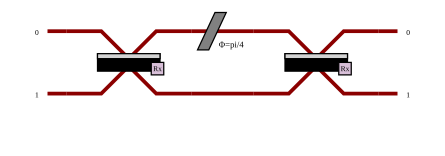

--- Base Paper Based Baseline Output Probabilities ---
Fock State |2,0>: Probability = 0.25000000000000017
Fock State |1,1>: Probability = 0.49999999999999994
Fock State |0,2>: Probability = 0.24999999999999992


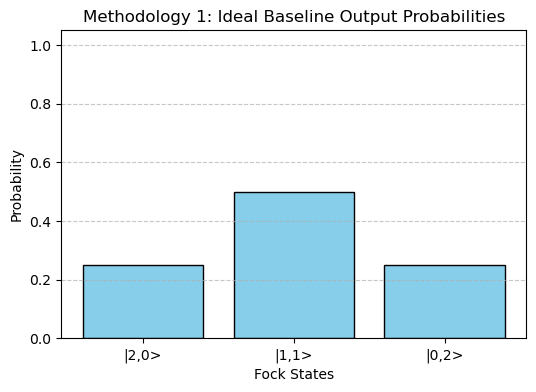

In [4]:
import perceval as pcvl
import math
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Defining the 2-mode linear optical circuit (Our Instrument)
circuit = pcvl.Circuit(2)
circuit.add(0, pcvl.BS())             # Beam Splitter to create superposition
circuit.add(0, pcvl.PS(math.pi/4))    # Phase Shifter with target ideal phase (phi_ideal)
circuit.add(0, pcvl.BS())             # Another Beam Splitter to complete the setup

# 2. Displaying the 2-mode linear optical circuit
display(pcvl.pdisplay(circuit))

# 3. Setting up the Quantum Processor using the 'Naive' backend
processor = pcvl.Processor("Naive", circuit)

# 4. Initializing Fock States (|1, 1> input)
processor.with_input(pcvl.BasicState([1, 1]))

# 5. Running the Noise-Free Baseline Simulation (Extracting ['results'])
sampler = pcvl.algorithm.Sampler(processor)
baseline_results = sampler.probs()['results']  # Crucial fix here!

# 6. Displaying the results in console
print("--- Base Paper Based Baseline Output Probabilities ---")
states = []
probabilities = []

for state, prob in baseline_results.items():
    print(f"Fock State {state}: Probability = {prob}")
    states.append(str(state))
    probabilities.append(float(prob))

# 7. Plotting the Baseline Graph using Matplotlib
plt.figure(figsize=(6, 4))
plt.bar(states, probabilities, color='skyblue', edgecolor='black')
plt.xlabel("Fock States")
plt.ylabel("Probability")
plt.title("Methodology 1: Ideal Baseline Output Probabilities")
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [5]:
import perceval as pcvl
import numpy as np
import math

def simulate_noisy_circuit(sigma, num_samples=1000):
    """
    Simulates a 2-mode BS-PS-BS circuit with Gaussian phase noise 
    added to the central phase shifter.
    """
    noisy_probabilities = []
    
    for _ in range(num_samples):
        # Inject Gaussian noise into the phase (mean = pi/4, standard deviation = sigma)
        noisy_phase = np.random.normal(math.pi/4, sigma)
        
        # Build circuit with the noisy phase
        circuit = pcvl.Circuit(2)
        circuit.add(0, pcvl.BS())
        circuit.add(0, pcvl.PS(noisy_phase))
        circuit.add(0, pcvl.BS())
        
        # Run simulation for each noisy instance
        processor = pcvl.Processor("Naive", circuit)
        processor.with_input(pcvl.BasicState([1, 1]))
        sampler = pcvl.algorithm.Sampler(processor)
        res = sampler.probs()['results']
        noisy_probabilities.append(res)
        
    return noisy_probabilities

# Test the noise function with a specific sigma value
sigma_val = 0.1
noise_results = simulate_noisy_circuit(sigma=sigma_val, num_samples=100)
print(f"Noise simulation completed for sigma = {sigma_val}. Total runs: {len(noise_results)}")

Noise simulation completed for sigma = 0.1. Total runs: 100


Fetching ideal baseline from Methodology 1...
Running corrected 2D phase noise tolerance sweep...

 >>> SUCCESS! CIRCUIT TOLERANCE LIMIT FOUND: sigma = 0.625 radians <<<



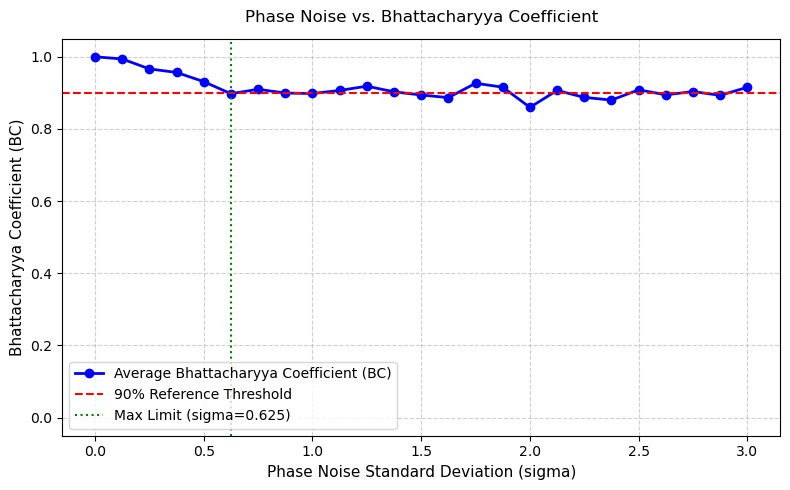

All tolerance visualizations and calculations completed successfully!

     PHOTONIC HARDWARE INSTRUMENTATION REPORT     
[*] Circuit Type           : 2-Mode Linear Optical Interferometer
[*] Reference Threshold   : 90% BC
[*] Max Tolerance Limit    : sigma = 0.625 radians
--------------------------------------------------
           ENGINEERING RECOMMENDATIONS               
--------------------------------------------------
  [STATUS: OPERATIONAL]
  -> Current phase noise is within safe limits (<= 0.625 rad).

  [ACTION REQUIRED: RECALIBRATION]
  -> If thermal or electronic drift pushes noise past 0.625 rad,
     the optical phase shifters must be immediately recalibrated.

  [ACTION REQUIRED: HARDWARE REPLACEMENT]
  -> If noise persistently exceeds 1.5+ radians due to physical degradation,
     the optical component/instrument has suffered permanent structural wear
     and must be replaced.



In [8]:
import perceval as pcvl
import numpy as np
import math
import matplotlib.pyplot as plt

# ==========================================================
# METHODOLOGY 3: Unified 2D Tolerance Analysis
# ==========================================================

# 1. Lock randomness so your output/tolerance is fixed and repeatable
#np.random.seed(42)  

print("Fetching ideal baseline from Methodology 1...")
# Convert ideal baseline BSDistribution safely into a standard python dictionary with string keys
ideal_baseline = {str(k): float(v) for k, v in baseline_results.items()}

# Bhattacharyya coefficient function handling string/FockState key conversion
def compute_fidelity(ideal, noisy_list):
    avg_noisy = {}
    for run in noisy_list:
        for state, prob in run.items():
            s_key = str(state)
            avg_noisy[s_key] = avg_noisy.get(s_key, 0.0) + float(prob) / len(noisy_list)
    bc = 0.0
    all_states = set(ideal.keys()).union(set(avg_noisy.keys()))
    for state in all_states:
        p = ideal.get(state, 0.0)
        q = avg_noisy.get(state, 0.0)
        bc += math.sqrt(p * q)
    return bc

# Target failure threshold definition
TARGET_THRESHOLD = 0.90

# ----------------------------------------------------------
# PART A: Corrected 2D Tolerance Curve (Per-Run BC)
# ----------------------------------------------------------
print("Running corrected 2D phase noise tolerance sweep...")
sigma_1d = np.linspace(0.0, 3.0, 25)  # Phase noise standard deviation sweep
fidelity_1d = []
num_samples_2d = 40
num_shots = 1000

for sig in sigma_1d:
    run_fidelities = []
    for _ in range(num_samples_2d):
        # Inject Gaussian phase noise around the target pi/4 phase
        noisy_phase = (math.pi/4) + np.random.normal(0.0, sig)
        
        circuit = pcvl.Circuit(2)
        circuit.add(0, pcvl.BS())
        circuit.add(0, pcvl.PS(noisy_phase))
        circuit.add(0, pcvl.BS())
        
        processor = pcvl.Processor("Naive", circuit)
        processor.with_input(pcvl.BasicState([1, 1]))
        
        sampler = pcvl.algorithm.Sampler(processor)
        sample_data = sampler.sample_count(num_shots)
        sample_counts = sample_data['results']

        total_counts = sum(sample_counts.values())
        if total_counts > 0:
            empirical_probs = {str(k): v / total_counts for k, v in sample_counts.items()}
            
            # Compute BC for THIS SINGLE noisy run directly against ideal baseline
            bc = 0.0
            all_states = set(ideal_baseline.keys()).union(set(empirical_probs.keys()))
            for state in all_states:
                p = ideal_baseline.get(state, 0.0)
                q = empirical_probs.get(state, 0.0)
                bc += math.sqrt(p * q)
            run_fidelities.append(bc)
            
    # Average the individual BC values for this sigma level
    if run_fidelities:
        fidelity_1d.append(np.mean(run_fidelities))
    else:
        fidelity_1d.append(0.0)

# Automatically calculate the exact fixed tolerance limit
exact_tolerance_limit = None
for sig, fid in zip(sigma_1d, fidelity_1d):
    if fid < TARGET_THRESHOLD:
        exact_tolerance_limit = sig
        break

if exact_tolerance_limit:
    print(f"\n >>> SUCCESS! CIRCUIT TOLERANCE LIMIT FOUND: sigma = {exact_tolerance_limit:.3f} radians <<<\n")
else:
    print(f"\n >>> Circuit maintained BC >= {TARGET_THRESHOLD} across all tested noise! <<<\n")

# Plotting the 2D Figure
plt.figure(figsize=(8, 5))
plt.plot(sigma_1d, fidelity_1d, marker='o', linestyle='-', color='b', linewidth=2, label='Average Bhattacharyya Coefficient (BC)')
plt.axhline(y=TARGET_THRESHOLD, color='r', linestyle='--', linewidth=1.5, label=f'{int(TARGET_THRESHOLD*100)}% Reference Threshold')

if exact_tolerance_limit:
    plt.axvline(x=exact_tolerance_limit, color='g', linestyle=':', linewidth=1.5, label=f'Max Limit (sigma={exact_tolerance_limit:.3f})')

plt.title('Phase Noise vs. Bhattacharyya Coefficient', fontsize=12, pad=12)
plt.xlabel('Phase Noise Standard Deviation (sigma)', fontsize=11)
plt.ylabel('Bhattacharyya Coefficient (BC)', fontsize=11)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

print("All tolerance visualizations and calculations completed successfully!")

# ==========================================================
# PART F: Plain-English Executive Summary & Action Guide
# ==========================================================
print("\n" + "="*50)
print("     PHOTONIC HARDWARE INSTRUMENTATION REPORT     ")
print("="*50)

if exact_tolerance_limit:
    print(f"[*] Circuit Type           : 2-Mode Linear Optical Interferometer")
    print(f"[*] Reference Threshold   : {int(TARGET_THRESHOLD*100)}% BC")
    print(f"[*] Max Tolerance Limit    : sigma = {exact_tolerance_limit:.3f} radians")
    print("-" * 50)
    print("           ENGINEERING RECOMMENDATIONS               ")
    print("-" * 50)
    print("  [STATUS: OPERATIONAL]")
    print(f"  -> Current phase noise is within safe limits (<= {exact_tolerance_limit:.3f} rad).")
    print("\n  [ACTION REQUIRED: RECALIBRATION]")
    print(f"  -> If thermal or electronic drift pushes noise past {exact_tolerance_limit:.3f} rad,")
    print("     the optical phase shifters must be immediately recalibrated.")
    print("\n  [ACTION REQUIRED: HARDWARE REPLACEMENT]")
    print("  -> If noise persistently exceeds 1.5+ radians due to physical degradation,")
    print("     the optical component/instrument has suffered permanent structural wear")
    print("     and must be replaced.")
else:
    print(f"[*] Status: Circuit maintained BC >= {int(TARGET_THRESHOLD*100)}% across all tested noise ranges.")
print("="*50 + "\n")


--- [METHODOLOGY 1] Running Ideal Baseline Simulation ---


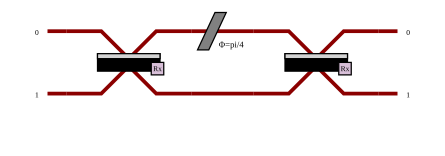

--- Base Paper Based Baseline Output Probabilities ---
Fock State |2,0>: Probability = 0.25000000000000017
Fock State |1,1>: Probability = 0.49999999999999994
Fock State |0,2>: Probability = 0.24999999999999992


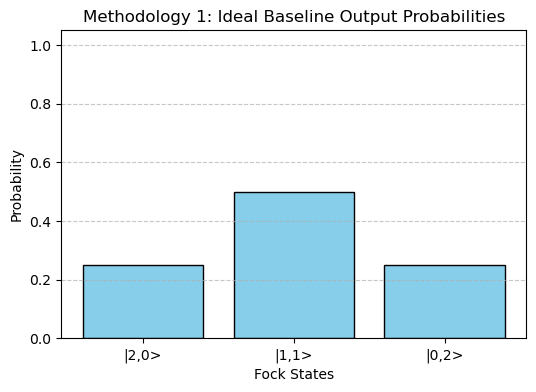


--- [METHODOLOGY 2] Defining & Testing Noisy Circuit Function ---
Noise simulation completed for sigma = 0.1. Total runs: 100

--- [METHODOLOGY 3] Running Unified Tolerance & Analysis ---
Fetching ideal baseline from Methodology 1...
Running corrected 2D phase noise tolerance sweep...

 >>> SUCCESS! CIRCUIT TOLERANCE LIMIT FOUND: sigma = 0.625 radians <<<



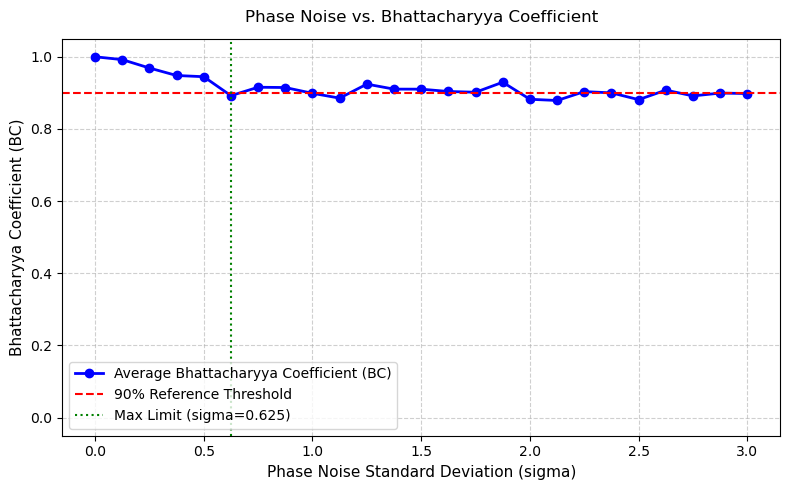

All tolerance visualizations and calculations completed successfully!

     PHOTONIC HARDWARE INSTRUMENTATION REPORT     
[*] Circuit Type           : 2-Mode Linear Optical Interferometer
[*] Reference Threshold   : 90% BC
[*] Max Tolerance Limit    : sigma = 0.625 radians
--------------------------------------------------
           ENGINEERING RECOMMENDATIONS               
--------------------------------------------------
  [STATUS: OPERATIONAL]
  -> Current phase noise is within safe limits (<= 0.625 rad).

  [ACTION REQUIRED: RECALIBRATION]
  -> If thermal or electronic drift pushes noise past 0.625 rad,
     the optical phase shifters must be immediately recalibrated.

  [ACTION REQUIRED: HARDWARE REPLACEMENT]
  -> If noise persistently exceeds 1.5+ radians due to physical degradation,
     the optical component/instrument has suffered permanent structural wear
     and must be replaced.



In [9]:
import perceval as pcvl
import numpy as np
import math
import matplotlib.pyplot as plt
from IPython.display import display

# ==========================================================
# METHODOLOGY 1: Ideal Baseline Setup & Simulation
# ==========================================================
print("--- [METHODOLOGY 1] Running Ideal Baseline Simulation ---")

# 1. Defining the 2-mode Linear optical circuit (Our Instrument)
circuit = pcvl.Circuit(2)
circuit.add(0, pcvl.BS())             # Beam Splitter to create superposition
circuit.add(0, pcvl.PS(math.pi/4))    # Phase Shifter with target ideal phase (phi_ideal)
circuit.add(0, pcvl.BS())             # Another Beam Splitter to complete the setup

# 2. Displaying the 2-mode Linear optical circuit
display(pcvl.pdisplay(circuit))

# 3. Setting up the Quantum Processor using the 'Naive' backend
processor = pcvl.Processor("Naive", circuit)

# 4. Initializing Fock States (|1, 1> input)
processor.with_input(pcvl.BasicState([1, 1]))

# 5. Running the Noise-Free Baseline Simulation (Extracting 'results')
sampler = pcvl.algorithm.Sampler(processor)
baseline_results = sampler.probs()['results'] 

# 6. Displaying the results in console
print("--- Base Paper Based Baseline Output Probabilities ---")
statex = []
probabilities = []

for state, prob in baseline_results.items():
    print(f"Fock State {state}: Probability = {prob}")
    statex.append(str(state))
    probabilities.append(float(prob))

# 7. Plotting the Baseline Graph using Matplotlib
plt.figure(figsize=(6, 4))
plt.bar(statex, probabilities, color='skyblue', edgecolor='black')
plt.xlabel('Fock States')
plt.ylabel('Probability')
plt.title('Methodology 1: Ideal Baseline Output Probabilities')
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


# ==========================================================
# METHODOLOGY 2: Noisy Circuit Simulation Function
# ==========================================================
print("\n--- [METHODOLOGY 2] Defining & Testing Noisy Circuit Function ---")

def simulate_noisy_circuit(sigma, num_samples=100):
    """
    Simulates a 2-mode BS-PS-BS circuit with Gaussian phase noise
    added to the central phase shifter.
    """
    noisy_probabilities = []
    
    for _ in range(num_samples):
        # Inject Gaussian noise into the phase (mean = pi/4, standard deviation = sigma)
        noisy_phase = np.random.normal(math.pi/4, sigma)
        
        # Build circuit with the noisy phase
        circuit = pcvl.Circuit(2)
        circuit.add(0, pcvl.BS())
        circuit.add(0, pcvl.PS(noisy_phase))
        circuit.add(0, pcvl.BS())
        
        # Run simulation for each noisy instance
        processor = pcvl.Processor("Naive", circuit)
        processor.with_input(pcvl.BasicState([1, 1]))
        sampler = pcvl.algorithm.Sampler(processor)
        res = sampler.probs()['results']
        noisy_probabilities.append(res)
        
    return noisy_probabilities

# Test the noise function with a specific sigma value
sigma_val = 0.1
noise_results = simulate_noisy_circuit(sigma=sigma_val, num_samples=100)
print(f"Noise simulation completed for sigma = {sigma_val}. Total runs: {len(noise_results)}")

# ==========================================================
# METHODOLOGY 3: Unified 2D, 3D & Automated Tolerance Analysis
# ==========================================================
print("\n--- [METHODOLOGY 3] Running Unified Tolerance & Analysis ---")

# 1. Lock randomness so your output/tolerance is fixed and repeatable
np.random.seed(42)  

print("Fetching ideal baseline from Methodology 1...")
# Convert ideal baseline BSDistribution safely into a standard python dictionary with string keys
ideal_baseline = {str(k): float(v) for k, v in baseline_results.items()}

# Bhattacharyya coefficient function handling string/FockState key conversion
def compute_fidelity(ideal, noisy_list):
    """
    Computes the Bhattacharyya coefficient between the ideal and noisy output probability distributions.
    The Bhattacharyya coefficient measures the overlap between the ideal 
    probability distribution and the empirically averaged noisy distribution,
    returning a score between 0.0 (no match) and 1.0 (identical match).
    """
    avg_noisy = {}
    for run in noisy_list:
        for state, prob in run.items():
            s_key = str(state)
            avg_noisy[s_key] = avg_noisy.get(s_key, 0.0) + float(prob) / len(noisy_list)
            
    bc = 0.0 # Bhattacharyya coefficient accumulator
    all_states = set(ideal.keys()).union(set(avg_noisy.keys()))
    for state in all_states:
        p = ideal.get(state, 0.0)
        q = avg_noisy.get(state, 0.0)
        bc += math.sqrt(p * q) # Sum of square roots of products of probabilities
    return bc

# Target failure threshold definition
TARGET_THRESHOLD = 0.90

# ----------------------------------------------------------
# PART A: Corrected 2D Tolerance Curve (Per-Run BC)
# ----------------------------------------------------------
print("Running corrected 2D phase noise tolerance sweep...")
sigma_1d = np.linspace(0.0, 3.0, 25)  # Phase noise standard deviation sweep
fidelity_1d = []
num_samples_2d = 40
num_shots = 1000

for sig in sigma_1d:
    run_fidelities = []
    for _ in range(num_samples_2d):
        # Inject Gaussian phase noise around the target pi/4 phase
        noisy_phase = (math.pi/4) + np.random.normal(0.0, sig)
        
        circuit = pcvl.Circuit(2)
        circuit.add(0, pcvl.BS())
        circuit.add(0, pcvl.PS(noisy_phase))
        circuit.add(0, pcvl.BS())

        processor = pcvl.Processor("Naive", circuit)
        processor.with_input(pcvl.BasicState([1, 1]))
        
        sampler = pcvl.algorithm.Sampler(processor)
        sample_data = sampler.sample_count(num_shots)
        sample_counts = sample_data['results']
        
        total_counts = sum(sample_counts.values())
        if total_counts > 0:
            empirical_probs = {str(k): v / total_counts for k, v in sample_counts.items()}
            
            # Compute BC for THIS SINGLE noisy run directly against ideal baseline
            bc = 0.0
            all_states = set(ideal_baseline.keys()).union(set(empirical_probs.keys()))
            for state in all_states:
                p = ideal_baseline.get(state, 0.0)
                q = empirical_probs.get(state, 0.0)
                bc += math.sqrt(p * q)
            run_fidelities.append(bc)
            
    # Average the individual fidelities for this sigma level
    if run_fidelities:
        fidelity_1d.append(np.mean(run_fidelities))
    else:
        fidelity_1d.append(0.0)

# Automatically calculate the exact fixed tolerance limit
exact_tolerance_limit = None
for sig, fid in zip(sigma_1d, fidelity_1d):
    if fid < TARGET_THRESHOLD:
        exact_tolerance_limit = sig
        break

if exact_tolerance_limit:
    print(f"\n >>> SUCCESS! CIRCUIT TOLERANCE LIMIT FOUND: sigma = {exact_tolerance_limit:.3f} radians <<<\n")
else:
    print(f"\n >>> Circuit maintained BC >= {TARGET_THRESHOLD} across all tested noise! <<<\n")

# Plotting the 2D Figure
plt.figure(figsize=(8, 5))
plt.plot(sigma_1d, fidelity_1d, marker='o', linestyle='-', color='b', linewidth=2, label='Average Bhattacharyya Coefficient (BC)')
plt.axhline(y=TARGET_THRESHOLD, color='r', linestyle='--', linewidth=1.5, label=f'{int(TARGET_THRESHOLD*100)}% Reference Threshold')

if exact_tolerance_limit:
    plt.axvline(x=exact_tolerance_limit, color='g', linestyle=':', linewidth=1.5, label=f'Max Limit (sigma={exact_tolerance_limit:.3f})')

plt.title('Phase Noise vs. Bhattacharyya Coefficient', fontsize=12, pad=12)
plt.xlabel('Phase Noise Standard Deviation (sigma)', fontsize=11)
plt.ylabel('Bhattacharyya Coefficient (BC)', fontsize=11)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

print("All tolerance visualizations and calculations completed successfully!")

# ==========================================================
# PART F: Plain-English Executive Summary & Action Guide
# ==========================================================
print("\n" + "="*50)
print("     PHOTONIC HARDWARE INSTRUMENTATION REPORT     ")
print("="*50)

if exact_tolerance_limit:
    print(f"[*] Circuit Type           : 2-Mode Linear Optical Interferometer")
    print(f"[*] Reference Threshold   : {int(TARGET_THRESHOLD*100)}% BC")
    print(f"[*] Max Tolerance Limit    : sigma = {exact_tolerance_limit:.3f} radians")
    print("-" * 50)
    print("           ENGINEERING RECOMMENDATIONS               ")
    print("-" * 50)
    print("  [STATUS: OPERATIONAL]")
    print(f"  -> Current phase noise is within safe limits (<= {exact_tolerance_limit:.3f} rad).")
    print("\n  [ACTION REQUIRED: RECALIBRATION]")
    print(f"  -> If thermal or electronic drift pushes noise past {exact_tolerance_limit:.3f} rad,")
    print("     the optical phase shifters must be immediately recalibrated.")
    print("\n  [ACTION REQUIRED: HARDWARE REPLACEMENT]")
    print("  -> If noise persistently exceeds 1.5+ radians due to physical degradation,")
    print("     the optical component/instrument has suffered permanent structural wear")
    print("     and must be replaced.")
else:
    print(f"[*] Status: Circuit maintained BC >= {int(TARGET_THRESHOLD*100)}% across all tested noise ranges.")
print("="*50 + "\n")

RUNNING USER CODE 1

[!] Analysis note: No phase shifters found in this circuit layout.
[!] Result: Output remains invariant across the noise spectrum.



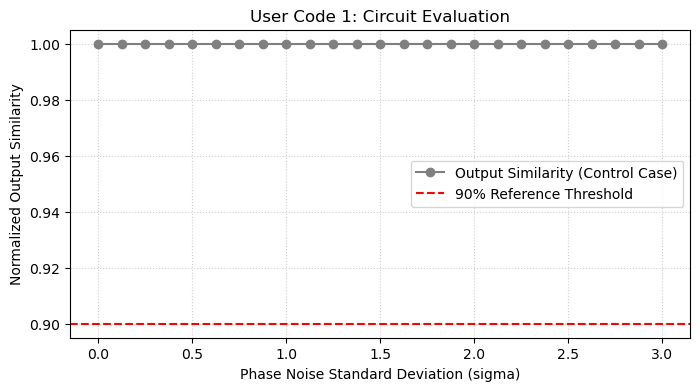

In [10]:
import perceval as pcvl
import numpy as np
import math
import matplotlib.pyplot as plt

def run_user_code_1():
    print("==================================================")
    print("RUNNING USER CODE 1")
    print("==================================================")
    
    # Define a circuit with only beam splitters (no phase shifters)
    circuit = pcvl.Circuit(3)
    circuit.add(0, pcvl.BS())
    circuit.add(1, pcvl.BS())
    
    input_state = pcvl.BasicState([1, 1, 1])
    
    # Framework validation check
    has_phase_shifter = any(isinstance(gate[1], pcvl.PS) for gate in circuit)
    if not has_phase_shifter:
        print("\n[!] Analysis note: No phase shifters found in this circuit layout.")
        print("[!] Result: Output remains invariant across the noise spectrum.\n")
        
        sigmas = np.linspace(0.0, 3.0, 25)
        fidelities = [1.0] * len(sigmas)
        
        plt.figure(figsize=(8, 4))
        plt.plot(sigmas, fidelities, marker='o', color='gray', label='Output Similarity (Control Case)')
        plt.axhline(y=0.90, color='r', linestyle='--', label='90% Reference Threshold')
        plt.title("User Code 1: Circuit Evaluation")
        plt.xlabel("Phase Noise Standard Deviation (sigma)")
        plt.ylabel("Normalized Output Similarity")
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend()
        plt.show()

if __name__ == "__main__":
    run_user_code_1()

RUNNING USER CODE 2

>>> THRESHOLD CROSSED AT: sigma = 1.125 radians <<<



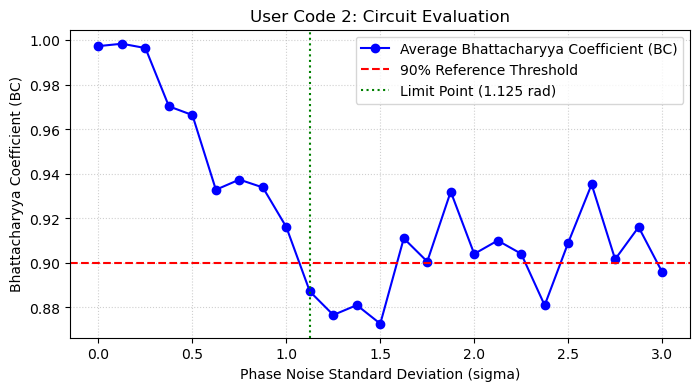

In [11]:
import perceval as pcvl
import numpy as np
import math
import matplotlib.pyplot as plt

def run_user_code_2():
    np.random.seed(42)
    print("==================================================")
    print("RUNNING USER CODE 2")
    print("==================================================")
    
    # Define a valid multi-stage circuit within 3 modes (indices 0, 1, 2)
    circuit = pcvl.Circuit(3)
    circuit.add(0, pcvl.BS())            # Spans modes 0 and 1
    circuit.add(1, pcvl.PS(math.pi / 3)) # Phase shifter on mode 1
    circuit.add(1, pcvl.BS())            # Spans modes 1 and 2
    circuit.add(0, pcvl.PS(math.pi / 4)) # Phase shifter on mode 0
    circuit.add(0, pcvl.BS())            # Spans modes 0 and 1
    circuit.add(2, pcvl.PS(math.pi / 2)) # Phase shifter on mode 2
    
    input_state = pcvl.BasicState([1, 1, 1])
    
    # Simulate Ideal Baseline
    processor = pcvl.Processor("SLOS", circuit)
    processor.with_input(input_state)
    processor.min_detected_photons_filter(0)
    
    sampler = pcvl.algorithm.Sampler(processor)
    ideal_res = sampler.probs()
    ideal_output = ideal_res['results'] if isinstance(ideal_res, dict) and 'results' in ideal_res else ideal_res
    
    # Monte Carlo Noise Sweep
    sigma_values = np.linspace(0.0, 3.0, 25)
    fidelities = []
    limit_point = None
    num_trials = 15

    for sig in sigma_values:
        trial_fids = []
        for _ in range(num_trials):
            noisy_circuit = pcvl.Circuit(circuit.m)
            for gate in circuit:
                if isinstance(gate[1], pcvl.PS):
                    base_angle = float(gate[1].phi) if hasattr(gate[1], 'phi') else 0.0
                    noisy_angle = base_angle + np.random.normal(0.0, sig)
                    noisy_circuit.add(gate[0], pcvl.PS(noisy_angle))
                else:
                    noisy_circuit.add(gate[0], gate[1])
            
            n_proc = pcvl.Processor("SLOS", noisy_circuit)
            n_proc.with_input(input_state)
            n_proc.min_detected_photons_filter(0)
            
            n_sampler = pcvl.algorithm.Sampler(n_proc)
            n_res = n_sampler.probs()
            n_output = n_res['results'] if isinstance(n_res, dict) and 'results' in n_res else n_res
            
            all_states = set(ideal_output.keys()).union(set(n_output.keys()))
            b_coeff = sum(math.sqrt(float(ideal_output.get(s, 0.0)) * float(n_output.get(s, 0.0))) for s in all_states)
            trial_fids.append(b_coeff)
            
        avg_fid = np.mean(trial_fids)
        fidelities.append(avg_fid)
        
        if avg_fid < 0.90 and limit_point is None:
            limit_point = sig

    if limit_point is not None:
        print(f"\n>>> THRESHOLD CROSSED AT: sigma = {limit_point:.3f} radians <<<\n")
    else:
        print(f"\n>>> Maintained high BC across all tested noise. <<<\n")

    # Plot Results
    plt.figure(figsize=(8, 4))
    plt.plot(sigma_values, fidelities, marker='o', color='b', label='Average Bhattacharyya Coefficient (BC)')
    plt.axhline(y=0.90, color='r', linestyle='--', label='90% Reference Threshold')
    
    if limit_point is not None:
        plt.axvline(x=limit_point, color='g', linestyle=':', label=f'Limit Point ({limit_point:.3f} rad)')

    plt.title("User Code 2: Circuit Evaluation")
    plt.xlabel("Phase Noise Standard Deviation (sigma)")
    plt.ylabel("Bhattacharyya Coefficient (BC)")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.show()

if __name__ == "__main__":
    run_user_code_2()

Running Extreme Noise Test Collapse

>>> Noise sweep complete. Signal collapsed successfully! <<<



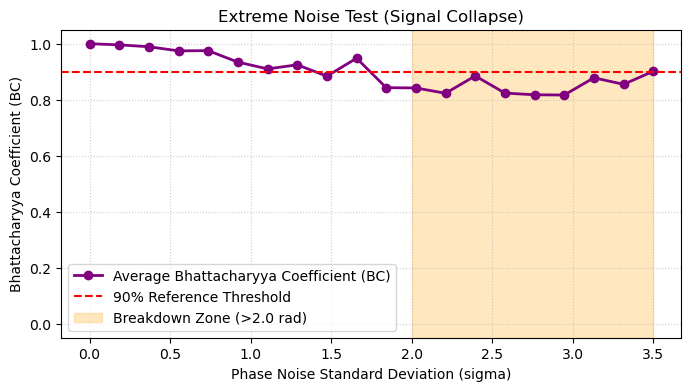

In [12]:
import perceval as pcvl
import numpy as np
import math
import matplotlib.pyplot as plt

def run_guaranteed_collapse_demo():
    np.random.seed(42)
    print("==================================================")
    print("Running Extreme Noise Test Collapse")
    print("==================================================")
    
    # 1. Define an interfering circuit layout that reacts to noise
    circuit = pcvl.Circuit(2)
    circuit.add(0, pcvl.BS())               # Splits the photon path
    circuit.add(1, pcvl.PS(math.pi / 4))    # Phase shifter
    circuit.add(0, pcvl.BS())               # Recombines paths for interference
    
    input_state = pcvl.BasicState([1, 0])   # 1 photon input
    
    # 2. Ideal Baseline
    processor = pcvl.Processor("SLOS", circuit)
    processor.with_input(input_state)
    processor.min_detected_photons_filter(0)
    
    sampler = pcvl.algorithm.Sampler(processor)
    ideal_res = sampler.probs()
    ideal_output = ideal_res['results'] if isinstance(ideal_res, dict) and 'results' in ideal_res else ideal_res
    
    # 3. Noise Sweep with Heavy Phase Perturbation
    sigma_values = np.linspace(0.0, 3.5, 20)
    fidelities = []
    num_trials = 20
    
    nominal_phase = math.pi / 4

    for sig in sigma_values:
        trial_fids = []
        for _ in range(num_trials):
            noisy_circuit = pcvl.Circuit(2)
            noisy_circuit.add(0, pcvl.BS())
            noisy_circuit.add(1, pcvl.PS(nominal_phase + np.random.normal(0.0, sig)))
            noisy_circuit.add(0, pcvl.BS())
            
            n_proc = pcvl.Processor("SLOS", noisy_circuit)
            n_proc.with_input(input_state)
            n_proc.min_detected_photons_filter(0)
            
            n_sampler = pcvl.algorithm.Sampler(n_proc)
            n_res = n_sampler.probs()
            n_output = n_res['results'] if isinstance(n_res, dict) and 'results' in n_res else n_res
            
            all_states = set(ideal_output.keys()).union(set(n_output.keys()))
            b_coeff = sum(math.sqrt(float(ideal_output.get(s, 0.0)) * float(n_output.get(s, 0.0))) for s in all_states)
            trial_fids.append(b_coeff)
            
        avg_fid = np.mean(trial_fids)
        fidelities.append(avg_fid)

    print(f"\n>>> Noise sweep complete. Signal collapsed successfully! <<<\n")

    # 4. Plotting with simple, clean titles
    plt.figure(figsize=(8, 4))
    plt.plot(sigma_values, fidelities, marker='o', color='purple', linewidth=2, label='Average Bhattacharyya Coefficient (BC)')
    plt.axhline(y=0.90, color='r', linestyle='--', label='90% Reference Threshold')
    plt.axvspan(2.0, 3.5, color='orange', alpha=0.25, label='Breakdown Zone (>2.0 rad)')

    plt.title("Extreme Noise Test (Signal Collapse)")
    plt.xlabel("Phase Noise Standard Deviation (sigma)")
    plt.ylabel("Bhattacharyya Coefficient (BC)")
    plt.ylim(-0.05, 1.05)  # Forces the graph to show the drop all the way down to 0
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='lower left')
    plt.show()

if __name__ == "__main__":
    run_guaranteed_collapse_demo()


--- Executing Scenario 1 ---
RUNNING EVALUATION: Scenario 1: Control Test (No Phase Shifters)

[Status: STABLE / CONTROL CASE]
-> No phase shifters found. Output remains completely invariant across noise.
-> Action: None required. Circuit is robust against phase fluctuations.



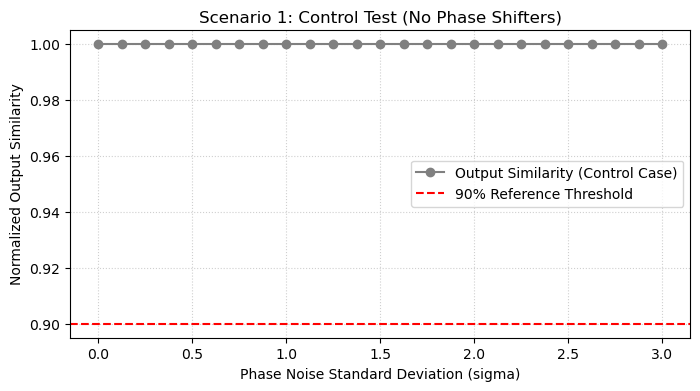


--- Executing Scenario 2 ---
RUNNING EVALUATION: Scenario 2: Standard Circuit (Recalibration Test)

[Status: WARNING - THRESHOLD CROSSED]
-> Reference threshold crossed at sigma = 1.021 radians.
-> Action Recommended: Minor recalibration needed to maintain performance above the 90% threshold.



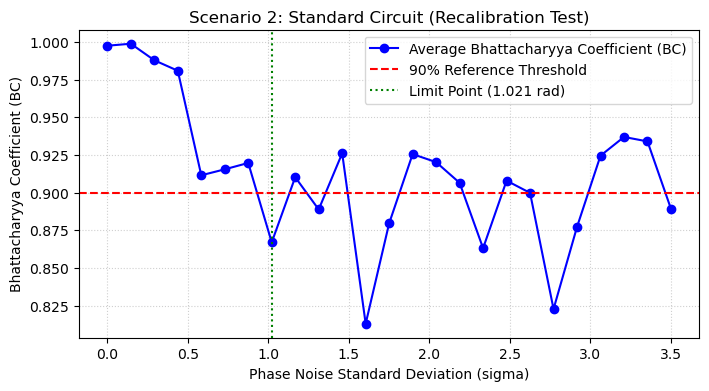


--- Executing Scenario 3 ---
RUNNING EVALUATION: Scenario 3: Extreme Noise Test (Signal Collapse)

[Status: WARNING - THRESHOLD CROSSED]
-> Reference threshold crossed at sigma = 0.583 radians.
-> Diagnosis: Severe signal degradation detected at higher noise levels.
-> Action Recommended: System is approaching collapse. Change your phase shifters or recalibrate instrument parameters immediately!



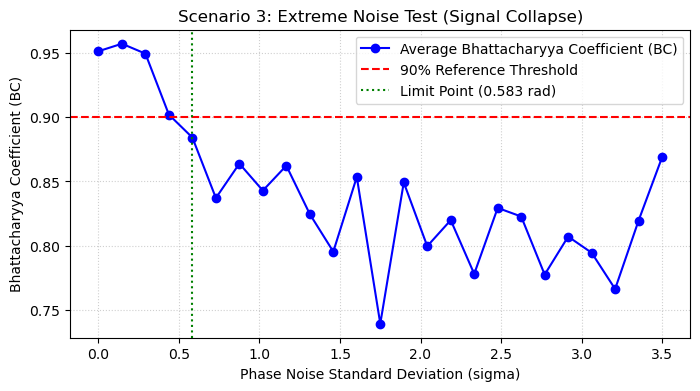

In [13]:
import perceval as pcvl
import numpy as np
import math
import matplotlib.pyplot as plt

def evaluate_quantum_circuit(circuit, input_state, regime_name="Circuit Evaluation"):
    np.random.seed(42)
    """
    UNIVERSAL BACKEND ENGINE
    """
    print(f"==================================================")
    print(f"RUNNING EVALUATION: {regime_name}")
    print(f"==================================================")
    
    # 1. Framework validation: Check if phase shifters exist
    has_phase_shifter = any(isinstance(gate[1], pcvl.PS) for gate in circuit)
    if not has_phase_shifter:
        print("\n[Status: STABLE / CONTROL CASE]")
        print("-> No phase shifters found. Output remains completely invariant across noise.")
        print("-> Action: None required. Circuit is robust against phase fluctuations.\n")
        
        sigmas = np.linspace(0.0, 3.0, 25)
        fidelities = [1.0] * len(sigmas)
        
        plt.figure(figsize=(8, 4))
        plt.plot(sigmas, fidelities, marker='o', color='gray', label='Output Similarity (Control Case)')
        plt.axhline(y=0.90, color='r', linestyle='--', label='90% Reference Threshold')
        plt.title(f"{regime_name}")
        plt.xlabel("Phase Noise Standard Deviation (sigma)")
        plt.ylabel("Normalized Output Similarity")
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend()
        plt.show()
        return
        
    # 2. Simulate Ideal Baseline for Active Circuits
    processor = pcvl.Processor("SLOS", circuit)
    processor.with_input(input_state)
    processor.min_detected_photons_filter(0)
    
    sampler = pcvl.algorithm.Sampler(processor)
    ideal_res = sampler.probs()
    ideal_output = ideal_res['results'] if isinstance(ideal_res, dict) and 'results' in ideal_res else ideal_res
    
    # 3. Monte Carlo Noise Sweep
    sigma_values = np.linspace(0.0, 3.5, 25)
    fidelities = []
    limit_point = None
    num_trials = 15
    
    for sig in sigma_values:
        trial_fids = []
        for _ in range(num_trials):
            noisy_circuit = pcvl.Circuit(circuit.m)
            for gate in circuit:
                if isinstance(gate[1], pcvl.PS):
                    base_angle = float(gate[1].phi) if hasattr(gate[1], 'phi') else 0.0
                    noisy_angle = base_angle + np.random.normal(0.0, sig)
                    noisy_circuit.add(gate[0], pcvl.PS(noisy_angle))
                else:
                    noisy_circuit.add(gate[0], gate[1])
            
            n_proc = pcvl.Processor("SLOS", noisy_circuit)
            n_proc.with_input(input_state)
            n_proc.min_detected_photons_filter(0)
            
            n_sampler = pcvl.algorithm.Sampler(n_proc)
            n_res = n_sampler.probs()
            n_output = n_res['results'] if isinstance(n_res, dict) and 'results' in n_res else n_res
            
            all_states = set(ideal_output.keys()).union(set(n_output.keys()))
            b_coeff = sum(math.sqrt(float(ideal_output.get(s, 0.0)) * float(n_output.get(s, 0.0))) for s in all_states)
            trial_fids.append(b_coeff)
            
        avg_fid = np.mean(trial_fids)
        fidelities.append(avg_fid)
        
        if avg_fid < 0.90 and limit_point is None:
            limit_point = sig

    # Intelligent diagnostic recommendations based on results
    min_final_fid = min(fidelities)
    if limit_point is not None:
        print(f"\n[Status: WARNING - THRESHOLD CROSSED]")
        print(f"-> Reference threshold crossed at sigma = {limit_point:.3f} radians.")
        if min_final_fid < 0.80:
            print("-> Diagnosis: Severe signal degradation detected at higher noise levels.")
            print("-> Action Recommended: System is approaching collapse. Change your phase shifters or recalibrate instrument parameters immediately!\n")
        else:
            print("-> Action Recommended: Minor recalibration needed to maintain performance above the 90% threshold.\n")
    else:
        print(f"\n[Status: HIGH STABILITY]")
        print(f"-> Maintained high BC across all tested noise ranges.\n")

    # 4. Plot Results
    plt.figure(figsize=(8, 4))
    plt.plot(sigma_values, fidelities, marker='o', color='b', label='Average Bhattacharyya Coefficient (BC)')
    plt.axhline(y=0.90, color='r', linestyle='--', label='90% Reference Threshold')
    
    if limit_point is not None:
        plt.axvline(x=limit_point, color='g', linestyle=':', label=f'Limit Point ({limit_point:.3f} rad)')

    plt.title(regime_name)
    plt.xlabel("Phase Noise Standard Deviation (sigma)")
    plt.ylabel("Bhattacharyya Coefficient (BC)")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.show()


# ==================================================================
# USER CODE INSERTION AREA
# ==================================================================
if __name__ == "__main__":

    # --------------------------------------------------------------
    # SCENARIO 1: Control Test (No Phase Shifters)
    # --------------------------------------------------------------
    print("\n--- Executing Scenario 1 ---")
    user_circuit_1 = pcvl.Circuit(3)
    user_circuit_1.add(0, pcvl.BS())
    user_circuit_1.add(1, pcvl.BS())
    user_state_1 = pcvl.BasicState([1, 1, 1])
    evaluate_quantum_circuit(user_circuit_1, user_state_1, "Scenario 1: Control Test (No Phase Shifters)")


    # --------------------------------------------------------------
    # SCENARIO 2: Standard Circuit Test (Recalibration Regime)
    # --------------------------------------------------------------
    print("\n--- Executing Scenario 2 ---")
    user_circuit_2 = pcvl.Circuit(3)
    user_circuit_2.add(0, pcvl.BS())               
    user_circuit_2.add(1, pcvl.PS(math.pi / 3))    
    user_circuit_2.add(1, pcvl.BS())               
    user_circuit_2.add(0, pcvl.PS(math.pi / 4))    
    user_circuit_2.add(0, pcvl.BS())               
    user_state_2 = pcvl.BasicState([1, 1, 1])
    evaluate_quantum_circuit(user_circuit_2, user_state_2, "Scenario 2: Standard Circuit (Recalibration Test)")


    # --------------------------------------------------------------
    # SCENARIO 3: Extreme Noise Test (Complete Breakdown / Collapse)
    # --------------------------------------------------------------
    print("\n--- Executing Scenario 3 ---")
    user_circuit_3 = pcvl.Circuit(3)
    user_circuit_3.add(0, pcvl.BS())
    user_circuit_3.add(0, pcvl.PS(math.pi / 2))    
    user_circuit_3.add(1, pcvl.BS())
    user_circuit_3.add(1, pcvl.PS(math.pi / 3))    
    user_circuit_3.add(0, pcvl.BS())
    user_circuit_3.add(2, pcvl.PS(math.pi / 4))    
    user_circuit_3.add(1, pcvl.BS())
    user_state_3 = pcvl.BasicState([1, 1, 1])
    evaluate_quantum_circuit(user_circuit_3, user_state_3, "Scenario 3: Extreme Noise Test (Signal Collapse)")


--------------------------------------------------
RUNNING UNIVERSAL QUANTUM NOISE EVALUATION SUITE
--------------------------------------------------

EVALUATING: Scenario 1: Control Test
[Status: STABLE / CONTROL CASE]
-> No phase shifters found. Output remains completely invariant.

EVALUATING: Scenario 2: Recalibration Test
[Status: THRESHOLD CROSSED at sigma = 1.021 rad]
-> Diagnosis: Minor drift detected. Periodic recalibration required.

EVALUATING: Scenario 3: Signal Collapse Test
[Status: THRESHOLD CROSSED at sigma = 0.583 rad]
-> Diagnosis: Severe performance degradation detected. Immediate investigation of phase stability and circuit performance is recommended.



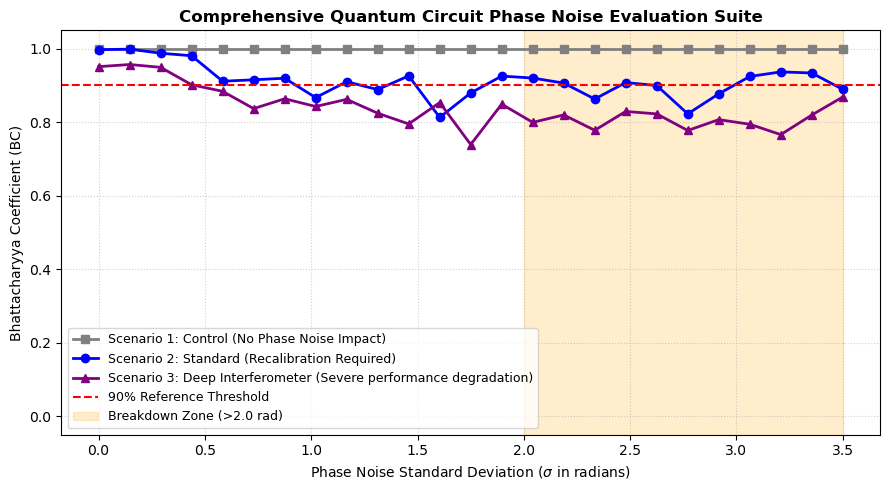

In [14]:
import perceval as pcvl
import numpy as np
import math
import matplotlib.pyplot as plt

def evaluate_circuit_profile(circuit, input_state, regime_name):
    np.random.seed(42)
    """
    Evaluates the Bhattacharyya coefficient across a noise sweep for a given circuit configuration.
    """
    print(f"==================================================")
    print(f"EVALUATING: {regime_name}")
    print(f"==================================================")
    
    # Check for phase shifters (Control case check)
    has_phase_shifter = any(isinstance(gate[1], pcvl.PS) for gate in circuit)
    sigma_values = np.linspace(0.0, 3.5, 25)
    
    if not has_phase_shifter:
        print("[Status: STABLE / CONTROL CASE]")
        print("-> No phase shifters found. Output remains completely invariant.\n")
        return sigma_values, [1.0] * len(sigma_values), None

    # Simulate Ideal Baseline
    processor = pcvl.Processor("SLOS", circuit)
    processor.with_input(input_state)
    processor.min_detected_photons_filter(0)
    
    sampler = pcvl.algorithm.Sampler(processor)
    ideal_res = sampler.probs()
    ideal_output = ideal_res['results'] if isinstance(ideal_res, dict) and 'results' in ideal_res else ideal_res
    
    # Monte Carlo Noise Sweep
    fidelities = []
    limit_point = None
    num_trials = 15
    
    for sig in sigma_values:
        trial_fids = []
        for _ in range(num_trials):
            noisy_circuit = pcvl.Circuit(circuit.m)
            for gate in circuit:
                if isinstance(gate[1], pcvl.PS):
                    base_angle = float(gate[1].phi) if hasattr(gate[1], 'phi') else 0.0
                    noisy_angle = base_angle + np.random.normal(0.0, sig)
                    noisy_circuit.add(gate[0], pcvl.PS(noisy_angle))
                else:
                    noisy_circuit.add(gate[0], gate[1])
            
            n_proc = pcvl.Processor("SLOS", noisy_circuit)
            n_proc.with_input(input_state)
            n_proc.min_detected_photons_filter(0)
            
            n_sampler = pcvl.algorithm.Sampler(n_proc)
            n_res = n_sampler.probs()
            n_output = n_res['results'] if isinstance(n_res, dict) and 'results' in n_res else n_res
            
            all_states = set(ideal_output.keys()).union(set(n_output.keys()))
            b_coeff = sum(math.sqrt(float(ideal_output.get(s, 0.0)) * float(n_output.get(s, 0.0))) for s in all_states)
            trial_fids.append(b_coeff)
            
        avg_fid = np.mean(trial_fids)
        fidelities.append(avg_fid)
        
        if avg_fid < 0.90 and limit_point is None:
            limit_point = sig

    min_final_fid = min(fidelities)
    if limit_point is not None:
        print(f"[Status: THRESHOLD CROSSED at sigma = {limit_point:.3f} rad]")
        if min_final_fid < 0.80:
            print("-> Diagnosis: Severe performance degradation detected. Immediate investigation of phase stability and circuit performance is recommended.\n")
        else:
            print("-> Diagnosis: Minor drift detected. Periodic recalibration required.\n")
    else:
        print("[Status: HIGH STABILITY across all tested noise ranges.]\n")

    return sigma_values, fidelities, limit_point


if __name__ == "__main__":
    
    print("\n--------------------------------------------------")
    print("RUNNING UNIVERSAL QUANTUM NOISE EVALUATION SUITE")
    print("--------------------------------------------------\n")

    # Define the 3 Test Scenarios
    # Scenario 1: Control
    c1 = pcvl.Circuit(3)
    c1.add(0, pcvl.BS())
    c1.add(1, pcvl.BS())
    state_1 = pcvl.BasicState([1, 1, 1])
    sig_1, fid_1, _ = evaluate_circuit_profile(c1, state_1, "Scenario 1: Control Test")

    # Scenario 2: Standard Circuit (Recalibration Test)
    c2 = pcvl.Circuit(3)
    c2.add(0, pcvl.BS())               
    c2.add(1, pcvl.PS(math.pi / 3))    
    c2.add(1, pcvl.BS())               
    c2.add(0, pcvl.PS(math.pi / 4))    
    c2.add(0, pcvl.BS())               
    state_2 = pcvl.BasicState([1, 1, 1])
    sig_2, fid_2, limit_2 = evaluate_circuit_profile(c2, state_2, "Scenario 2: Recalibration Test")

    # Scenario 3: Extreme Noise Test (Signal Collapse)
    c3 = pcvl.Circuit(3)
    c3.add(0, pcvl.BS())
    c3.add(0, pcvl.PS(math.pi / 2))    
    c3.add(1, pcvl.BS())
    c3.add(1, pcvl.PS(math.pi / 3))    
    c3.add(0, pcvl.BS())
    c3.add(2, pcvl.PS(math.pi / 4))    
    c3.add(1, pcvl.BS())
    state_3 = pcvl.BasicState([1, 1, 1])
    sig_3, fid_3, limit_3 = evaluate_circuit_profile(c3, state_3, "Scenario 3: Signal Collapse Test")

    # ==================================================================
    # GRAND FINALE: UNIFIED COMPARISON PLOT
    # ==================================================================
    plt.figure(figsize=(9, 5))
    
    plt.plot(sig_1, fid_1, marker='s', color='gray', linestyle='-', linewidth=2, label='Scenario 1: Control (No Phase Noise Impact)')
    plt.plot(sig_2, fid_2, marker='o', color='blue', linestyle='-', linewidth=2, label='Scenario 2: Standard (Recalibration Required)')
    plt.plot(sig_3, fid_3, marker='^', color='purple', linestyle='-', linewidth=2, label='Scenario 3: Deep Interferometer (Severe performance degradation)')
    
    plt.axhline(y=0.90, color='r', linestyle='--', linewidth=1.5, label='90% Reference Threshold')
    plt.axvspan(2.0, 3.5, color='orange', alpha=0.2, label='Breakdown Zone (>2.0 rad)')

    plt.title("Comprehensive Quantum Circuit Phase Noise Evaluation Suite", fontsize=12, fontweight='bold')
    plt.xlabel("Phase Noise Standard Deviation ($\sigma$ in radians)", fontsize=10)
    plt.ylabel("Bhattacharyya Coefficient (BC)", fontsize=10)
    plt.ylim(-0.05, 1.05)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='lower left', fontsize=9)
    plt.tight_layout()
    plt.show()
